ПідготовкаПісля запуску першого блоку коду, у матриці G:   Піксель зі значенням 0 знаходиться за координатами [0, 0] (повністю чорний).   Піксель зі значенням 128 знаходиться за координатами [1, 3] (середньо-сірий).   Піксель зі значенням 250 знаходиться за координатами [3, 5] (майже білий).   

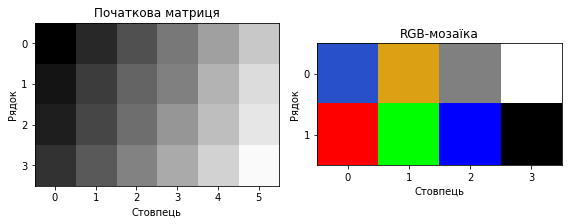

In [2]:
import numpy as np
import matplotlib.pyplot as plt

G = np.array([
    [ 0, 40,  80, 120, 160, 200],
    [20, 60, 100, 128, 180, 220],
    [30, 70, 110, 150, 190, 230],
    [50, 90, 130, 170, 210, 250]
], dtype=np.uint8)

RGB = np.array([
    [[ 40,  80, 200], [220, 160,  20], [128, 128, 128], [255, 255, 255]],
    [[255,   0,   0], [  0, 255,   0], [  0,   0, 255], [  0,   0,   0]]
], dtype=np.uint8)

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 3))
    for ax, (data, title) in zip(np.atleast_1d(axes), items):
        if data.ndim == 2:
            ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                      interpolation="nearest", origin="upper")
        else:
            ax.imshow(data, interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_title(title)
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
    plt.tight_layout()
    plt.show()

# Спочатку обмежуємо діапазон, потім округлюємо й повертаємо uint8.
def to_uint8(values):
    return np.rint(np.clip(values, 0, 255)).astype(np.uint8)

show_images([(G, "Початкова матриця"), (RGB, "RGB-мозаїка")])

Зміна яскравості
Ручні обчислення для k = 40:

Для p = 0: сума до обмеження = 0 + 40 = 40. Кінцеве значення після clip = 40.

Для p = 128: сума до обмеження = 128 + 40 = 168. Кінцеве значення після clip = 168.

Для p = 250: сума до обмеження = 250 + 40 = 290. Кінцеве значення після clip = 255 (значення обрізано до максимуму).

Форма й тип результату: (4, 6) uint8
Значень нижче 0 до обмеження: 0
Значень вище 255 до обмеження: 3
(0, 0) початкове = 0 до обмеження = 40 результат = 40
(1, 3) початкове = 128 до обмеження = 168 результат = 168
(3, 5) початкове = 250 до обмеження = 290 результат = 255


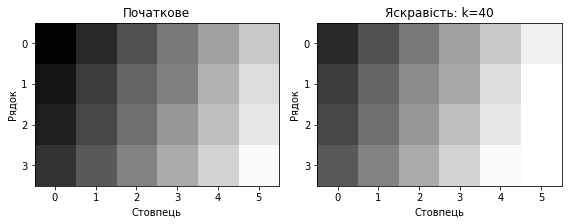

In [3]:
# Змінюйте k: -60, 0, 40, 100.
k = 40

raw = G.astype(np.int16) + k
bright = to_uint8(raw)

print("Форма й тип результату:", bright.shape, bright.dtype)
print("Значень нижче 0 до обмеження:", np.count_nonzero(raw < 0))
print("Значень вище 255 до обмеження:", np.count_nonzero(raw > 255))
for row, col in [(0, 0), (1, 3), (3, 5)]:
    print(
        (row, col), "початкове =", G[row, col],
        "до обмеження =", raw[row, col],
        "результат =", bright[row, col]
    )

show_images([(G, "Початкове"), (bright, f"Яскравість: k={k}")])

### Таблиця: Зміна яскравості

| `k` | Прогноз зміни зображення | Результат для p=0 | Результат для p=128 | Результат для p=250 | Значень нижче 0 до clip | Значень вище 255 до clip | Що спостерігали |
| ---: | --- | ---: | ---: | ---: | ---: | ---: | --- |
| -60 | Зображення стане набагато темнішим | 0 | 68 | 190 | 1 | 0 | Зображення стало темним, найтемніші квадрати злилися в суцільний чорний колір. |
| 0 | Зображення не зміниться | 0 | 128 | 250 | 0 | 0 | Зображення абсолютно ідентичне початковій матриці `G`. |
| 40 | Зображення стане світлішим | 40 | 168 | 255 | 0 | 0 | Зображення посвітлішало, найсвітліші квадрати злилися в суцільний білий. |
| 100 | Зображення стане дуже світлим (пересвіченим) | 100 | 228 | 255 | 0 | 3 | Зображення стало майже повністю білим, багато деталей втрачено. |

### Таблиця: Порогове зображення

| Поріг | Прогноз зміни кількості білих пікселів | Кількість білих пікселів | Частка білих пікселів | Що стало помітнішим або зникло |
| ---: | --- | ---: | ---: | --- |
| 64 | Зображення буде переважно білим | 19 | 0.7916 | Темні ділянки зникли, залишилися лише деталі найнижчої яскравості (чорні плями). |
| 128 | Білих і чорних пікселів буде приблизно порівну | 11 | 0.4583 | З'явився чіткий контраст між відносно темними та світлими областями. |
| 192 | Зображення буде переважно чорним | 4 | 0.1666 | Світлі ділянки зникли, видно лише найяскравіші об'єкти (білі плями). |

### Таблиця: Окремі коефіцієнти для RGB-каналів

| Коефіцієнти R, G, B | Прогноз RGB[0,0] | Фактичний RGB[0,0] | RGB сірого пікселя після зміни | Компонент понад 255 до clip | Що спостерігали |
| --- | --- | --- | --- | ---: | --- |
| `(1,1,1)` | `[40, 80, 200]` | `[40, 80, 200]` | `[128, 128, 128]` | 0 | Зображення не змінилося. |
| `(1.5,1,1)` | `[60, 80, 200]` | `[60, 80, 200]` | `[192, 128, 128]` | 0 | Додався червоний відтінок, сірий піксель став червонуватим. |
| `(1,0.5,1)` | `[40, 40, 200]` | `[40, 40, 200]` | `[128, 64, 128]` | 0 | Зеленого стало менше, пікселі набули пурпурового тону. |
| `(1,1,0)` | `[40, 80, 0]` | `[40, 80, 0]` | `[128, 128, 0]` | 0 | Синій колір повністю зник, зображення стало жовто-зеленим. |

Останній рядок оригіналу: [ 50  90 130 170 210 250]
Додавання в uint8: [ 90 130 170 210 250  34]
З обмеженням діапазону: [ 90 130 170 210 250 255]
Пікселів, які не відновилися: 3


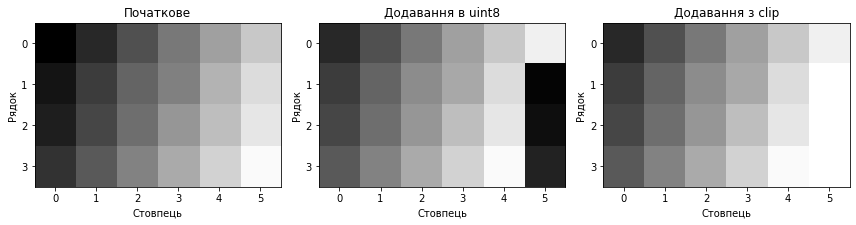

In [5]:
unsafe = G + np.uint8(40)
safe = to_uint8(G.astype(np.int16) + 40)

print("Останній рядок оригіналу:", G[-1])
print("Додавання в uint8:", unsafe[-1])
print("З обмеженням діапазону:", safe[-1])

restored_brightness = to_uint8(safe.astype(np.int16) - 40)
lost_pixels = np.count_nonzero(restored_brightness != G)
print("Пікселів, які не відновилися:", lost_pixels)

show_images([
    (G, "Початкове"),
    (unsafe, "Додавання в uint8"),
    (safe, "Додавання з clip")
])

Подвійний негатив відновив оригінал: True


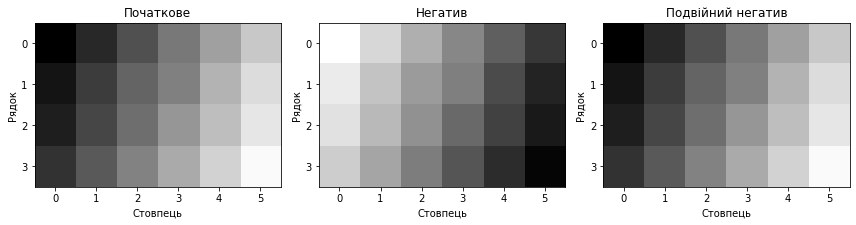

In [6]:
negative = np.uint8(255) - G
restored_negative = np.uint8(255) - negative

print("Подвійний негатив відновив оригінал:",
      np.array_equal(G, restored_negative))

show_images([
    (G, "Початкове"),
    (negative, "Негатив"),
    (restored_negative, "Подвійний негатив")
])

Форма RGB: (2, 4, 3)
Форма коефіцієнтів: (3,)
Форма результату: (2, 4, 3)
Компонент понад 255 до обмеження: 3
(0, 0) RGB до = [ 40  80 200] до обмеження = [ 60.  80. 200.] RGB після = [ 60  80 200]
(0, 1) RGB до = [220 160  20] до обмеження = [330. 160.  20.] RGB після = [255 160  20]
(0, 2) RGB до = [128 128 128] до обмеження = [192. 128. 128.] RGB після = [192 128 128]


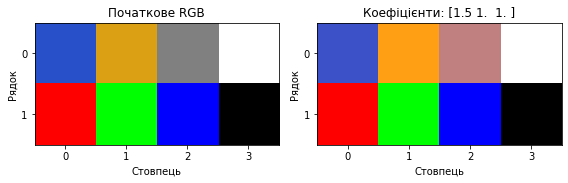

In [7]:
# Змінюйте gains: (1,1,1), (1.5,1,1), (1,0.5,1), (1,1,0).
gains = np.array([1.5, 1.0, 1.0])

if gains.shape != (3,) or not np.all(np.isfinite(gains)) or np.any(gains < 0):
    raise ValueError("Потрібні три скінченні невід'ємні коефіцієнти")

raw_rgb = RGB.astype(np.float64) * gains
scaled_rgb = to_uint8(raw_rgb)

print("Форма RGB:", RGB.shape)
print("Форма коефіцієнтів:", gains.shape)
print("Форма результату:", scaled_rgb.shape)
print("Компонент понад 255 до обмеження:",
      np.count_nonzero(raw_rgb > 255))
for row, col in [(0, 0), (0, 1), (0, 2)]:
    print(
        (row, col), "RGB до =", RGB[row, col],
        "до обмеження =", raw_rgb[row, col],
        "RGB після =", scaled_rgb[row, col]
    )

show_images([(RGB, "Початкове RGB"), (scaled_rgb, f"Коефіцієнти: {gains}")])

### Відповіді на питання

1. **Чому форма зображення зберігається після цих попіксельних операцій? Покажіть shape і dtype результатів bright, negative, binary, scaled_rgb.**
   Операції застосовуються поелементно до кожного пікселя матриці, не змінюючи їх кількість та структуру сітки. 
   * `bright`: shape `(4, 6)`, dtype `uint8`
   * `negative`: shape `(4, 6)`, dtype `uint8`
   * `binary`: shape `(4, 6)`, dtype `uint8`
   * `scaled_rgb`: shape `(2, 4, 3)`, dtype `uint8`

2. **Чому пряме додавання в uint8 може зробити світлий піксель темним?**
   Тип даних `uint8` підтримує значення лише в діапазоні від `0` до `255`. Якщо додати число до світлого пікселя (наприклад, `250 + 40 = 290`), відбувається цілочисельне переповнення (rollover) за модулем 256: `290 - 256 = 34`. Через це надто світлий піксель перетворюється на темно-сірий.

3. **Чому подвійний негатив відновлює зображення, а додавання з clip та подальше віднімання може не відновити його?**
   Операція негативу (`255 - p`) є зворотною і лінійною в межах діапазону `0–255`, дані при цьому не втрачаються. Додавання з подальшим обмеженням через `clip` є незворотним, оскільки всі значення, що перевищили 255 (наприклад, 290 або 310), жорстко обрізаються до `255`. Після такого «зрізу» інформація про початкове велике число губиться, і зворотне віднімання дає невірний результат.

4. **Як вибір `>` або `>=` впливає на піксель, який дорівнює порогу?**
   Якщо значення пікселя дорівнює пороговому (наприклад, `128`), то з оператором суворого порівняння `>` умова `128 > 128` дає `False` (піксель стає чорним). З оператором нересуворого порівняння `>=` умова `128 >= 128` дає `True` (піксель стає білим), що збільшує загальну кількість білих пікселів на одиницю.

5. **Як NumPy використовує три коефіцієнти для RGB-масивів? Чим `RGB * gains` відрізняється від матричного добутку?**
   NumPy використовує механізм **broadcasting** (розповсюдження): вектор `gains` розмірності `(3,)` автоматично узгоджується та застосовується до останньої осі (каналів R, G, B) кожного пікселя двовимірної сітки зображення. `RGB * gains` виконує *поелементне* множення каналів незалежно один від одного, на відміну від матричного добутку (`@`), який перемножає рядки на стовпці за законами лінійної алгебри.